# ⚽ Ligue 1 — Web scraping, nettoyage et analyse de données

**Projet de 1ʳᵉ année du cycle ingénieur** : scraper les résultats de tous les matchs d'une saison de Ligue 1, contrôler la qualité des données, puis les analyser (classement, avantage du terrain, course au titre, historique sur plusieurs saisons).

| | |
|---|---|
| **Source** | [TheFootData](https://thefootdata.com/competitions/ligue-1?saison=2025) : classement et résultats journée par journée, saisons 2014-15 à aujourd'hui |
| **Volume** | ~306 matchs par saison (34 journées × 9 matchs) + classements finaux de chaque saison |
| **Outils** | `requests`, `BeautifulSoup`, `pandas`, `matplotlib`, `seaborn` |
| **Sorties** | `data/raw/` (données brutes), `data/processed/` (tables nettoyées), `figures/` |

## Sommaire
1. Configuration
2. Source, éthique et stratégie de scraping
3. Scraping du classement et des 34 journées
4. API TheFootData (optionnel)
5. Nettoyage
6. Valeurs manquantes
7. Contrôles de cohérence
8. Valeurs aberrantes
9. Analyse et visualisations
10. Historique sur plusieurs saisons
11. Export
12. Conclusion

## 1. Configuration

In [1]:
import hashlib
import os
import re
import time
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.transforms import Bbox

# --- Paramètres ---------------------------------------------------------------
SEASON = 2025                          # 2025 = saison 2025-26
HISTORY_SEASONS = range(2014, SEASON + 1)   # classements finaux pour l'historique
REFRESH = False        # True = re-scraper même si les données brutes existent déjà
REQUEST_DELAY = 3      # secondes entre deux requêtes réseau (politesse envers le site)

BASE_URL = "https://thefootdata.com/competitions/ligue-1"
HEADERS = {"User-Agent": "Ligue1ScrapingProject/1.0 (student project; https://github.com/<mohamedazizameur-ai >/ligue1-scraping-alternative-2)"}

# --- Chemins -------------------------------------------------------------------
DATA_RAW, DATA_PROCESSED = Path("data/raw"), Path("data/processed")
CACHE, FIGURES = Path("data/cache"), Path("figures")
for folder in (DATA_RAW, DATA_PROCESSED, CACHE, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# --- Style des graphiques -----------------------------------------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, LIGHT_GREY = "#b4b2ab", "#dcdad4"
INK, INK_2 = "#0b0b0b", "#52514e"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
})
pd.set_option("display.width", 140)


def season_label(season: int) -> str:
    return f"{season}-{str(season + 1)[-2:]}"


LABEL_SPOTS = [(6, 4, "left", "bottom"), (6, -4, "left", "top"), (-6, 4, "right", "bottom"),
               (-6, -4, "right", "top"), (0, 9, "center", "bottom"), (0, -9, "center", "top"),
               (12, 12, "left", "bottom"), (12, -12, "left", "top"),
               (-12, 12, "right", "bottom"), (-12, -12, "right", "top")]


def place_labels(ax, xs, ys, texts, obstacles=(), fontsize=8.5, leader=False):
    """Étiquette chaque point en choisissant la position qui chevauche le moins
    les autres étiquettes, les points et les textes déjà présents (obstacles).
    leader=True : étiquettes plus éloignées, reliées au point par un trait."""
    scale = 3 if leader else 1
    arrow = dict(arrowstyle="-", color=INK_2, lw=0.8, shrinkA=0, shrinkB=4) if leader else None
    renderer = ax.figure.canvas.get_renderer()
    taken = [o.get_window_extent(renderer) for o in obstacles]
    points = [Bbox.from_bounds(px - 5, py - 5, 10, 10)
              for px, py in ax.transData.transform(np.column_stack([xs, ys]))]
    for i, (x, y, text) in enumerate(zip(xs, ys, texts)):
        best = None
        for dx, dy, ha, va in LABEL_SPOTS:
            ann = ax.annotate(text, (x, y), xytext=(dx * scale, dy * scale),
                              textcoords="offset points", ha=ha, va=va,
                              fontsize=fontsize, color=INK, arrowprops=arrow)
            box = ann.get_window_extent(renderer)
            score = (sum(box.overlaps(b) for b in taken)
                     + sum(box.overlaps(b) for j, b in enumerate(points) if j != i)
                     + 5 * (not ax.bbox.contains(box.x0, box.y0) or not ax.bbox.contains(box.x1, box.y1)))
            if best is None or score < best[0]:
                if best:
                    best[1].remove()
                best = (score, ann, box)
            else:
                ann.remove()
            if score == 0:
                break
        taken.append(best[2])

print(f"Saison analysée : {season_label(SEASON)}")

Saison analysée : 2025-26


## 2. Source, éthique et stratégie de scraping

### Pourquoi TheFootData ?
Les versions précédentes du projet utilisaient FBref (bloqué par Cloudflare : erreur `403`) puis Wikipédia (un seul tableau de classement par saison). [TheFootData](https://thefootdata.com) publie, pour chaque saison depuis 2014-15 :
- le **classement** (points, victoires, nuls, défaites, buts, forme) ;
- les **résultats de chaque journée** (date, équipe à domicile, score, équipe à l'extérieur).

Les pages sont générées côté serveur : les tableaux sont directement dans le HTML, sans JavaScript, ce qui permet de les lire avec `requests` et `pandas.read_html`.

### Règles respectées
Les [conditions d'utilisation](https://thefootdata.com/cgu) du site interdisent de perturber le service, avec l'exemple de l'« accès massif automatisé ». Le scraper est donc conçu pour être **sobre** :
- **une pause** de `REQUEST_DELAY` secondes entre deux requêtes ;
- un **cache disque** (`data/cache/`) : une page déjà téléchargée n'est jamais redemandée ;
- les données brutes sont enregistrées en CSV dans `data/raw/` ; tant que `REFRESH = False`, les exécutions suivantes ne font **aucune requête** ;
- un `User-Agent` qui identifie le projet ;
- environ 50 requêtes au total pour une première exécution (34 journées + 1 classement + ~12 saisons d'historique).

### URLs utilisées
| Page | URL |
|---|---|
| Classement d'une saison | `…/ligue-1?saison=2025&organisme=federation-francaise` |
| Résultats d'une journée | `…/ligue-1?saison=2025&organisme=federation-francaise&journee=12` |

## 3. Scraping du classement et des 34 journées

In [2]:
class ScrapingError(Exception):
    pass


_last_request = 0.0


def get_page(params: dict, retries: int = 3) -> str:
    """Renvoie le HTML d'une page : depuis le cache si possible, sinon via le réseau."""
    global _last_request
    params = {"saison": params["saison"], "organisme": "federation-francaise",
              **{k: v for k, v in params.items() if k != "saison"}}
    key = "_".join(f"{k}-{v}" for k, v in params.items() if k != "organisme")
    cache_file = CACHE / f"ligue-1_{key}.html"
    if cache_file.exists():
        return cache_file.read_text(encoding="utf-8")

    for attempt in range(1, retries + 1):
        wait = REQUEST_DELAY - (time.time() - _last_request)
        if wait > 0:
            time.sleep(wait)                      # pause entre deux requêtes
        _last_request = time.time()
        try:
            response = requests.get(BASE_URL, params=params, headers=HEADERS, timeout=20)
        except requests.RequestException as exc:
            print(f"  tentative {attempt}/{retries} échouée : {type(exc).__name__}")
            continue
        if response.status_code == 429:           # trop de requêtes : on respecte Retry-After
            time.sleep(int(response.headers.get("Retry-After", 30)))
            continue
        if response.status_code != 200:
            raise ScrapingError(f"code HTTP {response.status_code} pour {response.url}")
        cache_file.write_text(response.text, encoding="utf-8")
        return response.text
    raise ScrapingError(f"impossible de télécharger la page {params}")


def read_tables(html: str, required: set[str]) -> list[pd.DataFrame]:
    """Tous les tableaux HTML de la page qui contiennent les colonnes demandées."""
    try:
        tables = pd.read_html(StringIO(html), thousands=None)
    except ValueError:                             # aucune balise <table>
        tables = []
    found = []
    for table in tables:
        table.columns = [str(c[-1] if isinstance(c, tuple) else c).strip() for c in table.columns]
        if required <= set(table.columns):
            found.append(table)
    return found


def parse_standings(html: str) -> pd.DataFrame:
    tables = read_tables(html, {"Équipe", "Pts", "J"})
    if not tables:
        raise ScrapingError("tableau du classement introuvable (structure de la page modifiée ?)")
    return tables[0]


def parse_matchday(html: str, matchday: int) -> pd.DataFrame:
    tables = read_tables(html, {"Domicile", "Score", "Extérieur"})
    if not tables:
        raise ScrapingError(f"tableau des résultats introuvable pour la journée {matchday}")
    matches = pd.concat(tables, ignore_index=True)   # un tableau par date sur certaines pages
    return matches.assign(matchday=matchday)


def scrape_season(season: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Classement + résultats de toutes les journées d'une saison."""
    standings = parse_standings(get_page({"saison": season})).assign(season=season)
    n_matchdays = 2 * (len(standings) - 1)          # chaque équipe affronte les autres 2 fois
    days = []
    for day in range(1, n_matchdays + 1):
        days.append(parse_matchday(get_page({"saison": season, "journee": day}), day))
        print(f"\r  journées scrapées : {day}/{n_matchdays}", end="")
    print()
    return standings, pd.concat(days, ignore_index=True).assign(season=season)


def load_or_scrape(season: int) -> tuple[pd.DataFrame, pd.DataFrame, str]:
    """Charge les CSV bruts s'ils existent (aucune requête), sinon scrape le site."""
    f_standings = DATA_RAW / f"standings_{season}.csv"
    f_matches = DATA_RAW / f"matches_{season}.csv"
    if not REFRESH and f_standings.exists() and f_matches.exists():
        return (pd.read_csv(f_standings, sep=";"), pd.read_csv(f_matches, sep=";"),
                f"fichiers bruts locaux ({DATA_RAW})")
    print(f"Scraping de la saison {season_label(season)} sur thefootdata.com…")
    standings, matches = scrape_season(season)
    standings.to_csv(f_standings, index=False, sep=";")
    matches.to_csv(f_matches, index=False, sep=";")
    return standings, matches, "thefootdata.com (scraping en direct)"


raw_standings, raw_matches, source = load_or_scrape(SEASON)
print(f"Source : {source}")
print(f"Classement : {raw_standings.shape[0]} équipes | Résultats : {raw_matches.shape[0]} lignes")
raw_matches.head(10)

Source : fichiers bruts locaux (data\raw)
Classement : 18 équipes | Résultats : 306 lignes


,Date,Domicile,Score,Extérieur,matchday,season
0,ven 15 août,Stade Rennais Fc,1 – 0,Olympique Marseille,1,2025
1,sam 16 août,As Monaco Fc,3 – 1,Le Havre Ac,1,2025
2,sam 16 août,Lens Rc,0 – 1,Olympique Lyonnais,1,2025
3,sam 16 août,Ogc Nice Ca,0 – 1,Toulouse Fc,1,2025
4,dim 17 août,Stade Brestois 29,3 – 3,Lille Losc Associati,1,2025
5,dim 17 août,Angers Sco,1 – 0,Paris Fc,1,2025
6,dim 17 août,Fc Nantes,0 – 1,Paris Saint-Germain,1,2025
7,dim 17 août,Aj Auxerre,1 – 0,Lorient Fc,1,2025
8,dim 17 août,Metz Fc,0 – 1,Strasbourg Rcsa,1,2025
9,ven 22 août,Paris Saint-Germain,1 – 0,Angers Sco,2,2025


## 4. API TheFootData (optionnel)

Le site propose aussi une API (`X-API-Key: tfd_…`, 1 000 requêtes/heure avec une clé). D'après sa [documentation](https://thefootdata.com/api), elle **n'est pas encore ouverte au public** et son adresse n'est pas publiée : cette section est donc facultative et n'empêche pas le reste du notebook de fonctionner.

**La clé ne doit jamais être écrite dans le notebook** (elle serait publiée sur GitHub). On la place dans un fichier `.env` à la racine du projet, exclu du dépôt par `.gitignore` :
```
TFD_API_KEY=tfd_...
TFD_API_BASE=https://adresse-de-l-api
```

In [3]:
def load_env(path: Path = Path(".env")) -> None:
    """Charge les variables d'un fichier .env (sans dépendance externe)."""
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if "=" in line and not line.lstrip().startswith("#"):
                name, value = line.split("=", 1)
                os.environ.setdefault(name.strip(), value.strip().strip('"').strip("'"))


load_env()
API_KEY, API_BASE = os.getenv("TFD_API_KEY"), os.getenv("TFD_API_BASE")


def api_get(path: str, **params) -> dict:
    response = requests.get(f"{API_BASE.rstrip('/')}{path}", params=params, timeout=20,
                            headers={**HEADERS, "X-API-Key": API_KEY})
    print(f"GET {path} → {response.status_code} "
          f"(quota restant : {response.headers.get('X-RateLimit-Remaining', '?')})")
    response.raise_for_status()
    return response.json()


api_competitions = None
if not (API_KEY and API_BASE):
    print("API non configurée (TFD_API_KEY / TFD_API_BASE absents du fichier .env) : section ignorée.")
else:
    print(f"Clé chargée : {API_KEY[:6]}…{API_KEY[-4:]}")   # on n'affiche jamais la clé entière
    try:
        print(api_get("/v1/quota"))
        result = api_get("/v1/competitions", q="Ligue 1", season=SEASON, limit=20)
        api_competitions = pd.json_normalize(result.get("items", []))
    except (requests.RequestException, ValueError) as exc:
        print(f"Appel à l'API impossible : {exc}")
api_competitions

API non configurée (TFD_API_KEY / TFD_API_BASE absents du fichier .env) : section ignorée.


## 5. Nettoyage

| Problème | Exemple brut | Traitement |
|---|---|---|
| Noms officiels peu lisibles | `Lille Losc Associati`, `Ogc Nice Ca` | table de correspondance vers un nom court (`Lille`, `Nice`) |
| Score en texte | `5 – 4` | deux colonnes entières `home_goals`, `away_goals` |
| Match sans score | `-`, horaire, vide | score manquant, statut `non joué` (jamais compté 0-0) |
| Date sans année | `dim 17 mai` | année déduite de la saison (août–décembre → 1ʳᵉ année, janvier–juillet → 2ᵉ) |
| Différence de buts signée | `+45`, `-3` | entier |
| Forme en lettres | `VNVVD` | points sur les 5 derniers matchs (V = 3, N = 1, D = 0) |

In [4]:
TEAM_NAMES = {
    "Paris Saint-Germain": "Paris SG", "Lens Rc": "Lens", "Lille Losc Associati": "Lille",
    "Olympique Lyonnais": "Lyon", "Olympique Marseille": "Marseille", "Stade Rennais Fc": "Rennes",
    "As Monaco Fc": "Monaco", "Strasbourg Rcsa": "Strasbourg", "Toulouse Fc": "Toulouse",
    "Lorient Fc": "Lorient", "Paris Fc": "Paris FC", "Stade Brestois 29": "Brest",
    "Angers Sco": "Angers", "Le Havre Ac": "Le Havre", "Aj Auxerre": "Auxerre",
    "Ogc Nice Ca": "Nice", "Fc Nantes": "Nantes", "Metz Fc": "Metz",
}
# Pour les clubs absents de la table (autres saisons) : on retire les sigles juridiques courants
LEGAL_TOKENS = {"fc", "ac", "rc", "rcsa", "sco", "ca", "as", "aj", "ogc", "losc", "associati", "sc", "fco", "us"}


def short_name(name: str) -> str:
    name = re.sub(r"\s+", " ", str(name)).strip()
    if name in TEAM_NAMES:
        return TEAM_NAMES[name]
    words = [w for w in name.split() if w.lower() not in LEGAL_TOKENS]
    return " ".join(words) or name


MONTHS = {"jan": 1, "fév": 2, "fev": 2, "mar": 3, "avr": 4, "mai": 5, "juin": 6, "juil": 7,
          "aoû": 8, "aou": 8, "sep": 9, "oct": 10, "nov": 11, "déc": 12, "dec": 12}


def parse_date(text: str, season: int) -> pd.Timestamp:
    """'dim 17 mai' -> 2026-05-17 pour la saison 2025-26."""
    m = re.search(r"(\d{1,2})\s+([a-zéû]+)", str(text).lower())
    if not m:
        return pd.NaT
    day, word = int(m.group(1)), m.group(2)
    month = next((n for prefix, n in sorted(MONTHS.items(), key=lambda kv: -len(kv[0]))
                  if word.startswith(prefix)), None)
    if month is None:
        return pd.NaT
    year = season if month >= 7 else season + 1
    return pd.Timestamp(year=year, month=month, day=day)


def clean_matches(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.rename(columns={"Date": "date_text", "Domicile": "home", "Extérieur": "away",
                             "Score": "score"}).copy()
    df["home"], df["away"] = df["home"].map(short_name), df["away"].map(short_name)
    goals = df["score"].astype(str).str.extract(r"(\d+)\s*[–—-]\s*(\d+)")
    df["home_goals"] = pd.to_numeric(goals[0], errors="coerce").astype("Int64")
    df["away_goals"] = pd.to_numeric(goals[1], errors="coerce").astype("Int64")
    df["status"] = np.where(df["home_goals"].isna(), "non joué", "joué")
    df["date"] = [parse_date(t, s) for t, s in zip(df["date_text"], df["season"])]
    df["total_goals"] = df["home_goals"] + df["away_goals"]
    hg, ag = df["home_goals"].astype(float), df["away_goals"].astype(float)   # NaN si non joué
    df["result"] = np.select([hg > ag, hg < ag, hg == ag],
                             ["Victoire domicile", "Victoire extérieur", "Match nul"], default=None)
    return df[["season", "matchday", "date", "date_text", "home", "away", "home_goals",
               "away_goals", "total_goals", "result", "status"]]


def clean_standings(raw: pd.DataFrame) -> pd.DataFrame:
    df = raw.rename(columns={"#": "rank", "Équipe": "team", "Pts": "points", "J": "played",
                             "G": "wins", "N": "draws", "P": "losses", "bp": "goals_for",
                             "bc": "goals_against", "diff": "goal_diff", "Forme": "form"}).copy()
    df["team"] = df["team"].map(short_name)
    for col in ["rank", "points", "played", "wins", "draws", "losses",
                "goals_for", "goals_against", "goal_diff"]:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace("−", "-").str.replace("+", ""),
                                errors="coerce").astype("Int64")
    if "form" in df.columns:
        letters = df["form"].astype(str).str.findall(r"[VND]")
        df["form_points"] = letters.apply(lambda r: sum({"V": 3, "N": 1}.get(x, 0) for x in r))
    keep = ["season", "rank", "team", "played", "wins", "draws", "losses", "goals_for",
            "goals_against", "goal_diff", "points", "form", "form_points"]
    return df[[c for c in keep if c in df.columns]]


matches = clean_matches(raw_matches)
standings = clean_standings(raw_standings)
matches.head(10)

,season,matchday,date,date_text,home,away,home_goals,away_goals,total_goals,result,status
0,2025,1,2025-08-15,ven 15 août,Rennes,Marseille,1,0,1,Victoire domicile,joué
1,2025,1,2025-08-16,sam 16 août,Monaco,Le Havre,3,1,4,Victoire domicile,joué
2,2025,1,2025-08-16,sam 16 août,Lens,Lyon,0,1,1,Victoire extérieur,joué
3,2025,1,2025-08-16,sam 16 août,Nice,Toulouse,0,1,1,Victoire extérieur,joué
4,2025,1,2025-08-17,dim 17 août,Brest,Lille,3,3,6,Match nul,joué
5,2025,1,2025-08-17,dim 17 août,Angers,Paris FC,1,0,1,Victoire domicile,joué
6,2025,1,2025-08-17,dim 17 août,Nantes,Paris SG,0,1,1,Victoire extérieur,joué
7,2025,1,2025-08-17,dim 17 août,Auxerre,Lorient,1,0,1,Victoire domicile,joué
8,2025,1,2025-08-17,dim 17 août,Metz,Strasbourg,0,1,1,Victoire extérieur,joué
9,2025,2,2025-08-22,ven 22 août,Paris SG,Angers,1,0,1,Victoire domicile,joué


In [5]:
standings

,season,rank,team,played,wins,draws,losses,goals_for,goals_against,goal_diff,points,form,form_points
0,2025,1,Paris SG,34,24,4,6,74,29,45,76,VNVVD,10
1,2025,2,Lens,34,22,4,8,66,35,31,70,NNVDV,8
2,2025,3,Lille,34,18,7,9,52,37,15,61,NVNVD,8
3,2025,4,Lyon,34,18,6,10,53,40,13,60,VVVDD,9
4,2025,5,Marseille,34,18,5,11,63,45,18,59,DNDVV,7
5,2025,6,Rennes,34,17,8,9,59,50,9,59,VVDVD,9
6,2025,7,Monaco,34,16,6,12,60,54,6,54,NNVDD,5
7,2025,8,Strasbourg,34,15,8,11,58,47,11,53,VDNVV,10
8,2025,9,Toulouse,34,12,9,13,47,46,1,45,DNVVN,8
9,2025,10,Lorient,34,11,12,11,48,51,-3,45,VDNVD,7


## 6. Valeurs manquantes

In [6]:
print("Valeurs manquantes par colonne (matchs) :")
print(matches.isna().sum()[lambda s: s > 0].to_string() or "aucune")
unplayed = matches[matches["status"] == "non joué"]
print(f"\nMatchs sans score : {len(unplayed)}")
unplayed

Valeurs manquantes par colonne (matchs) :
Series([], )

Matchs sans score : 0


,season,matchday,date,date_text,home,away,home_goals,away_goals,total_goals,result,status


**Décision : pas d'imputation.** Un score manquant correspond à un match **non joué** (reporté, à venir, ou arrêté). Lui attribuer un score (moyenne, 0-0…) inventerait un résultat qui n'existe pas et fausserait le classement : c'est d'ailleurs la règle suivie par le site (« un match sans score n'est jamais compté 0-0 »). Ces matchs sont donc conservés avec le statut `non joué` et **exclus des calculs**.

Une **date** manquante, en revanche, n'empêche pas l'analyse des résultats : on peut la laisser vide, ou la compléter à partir des autres matchs de la même journée (ils se jouent le même week-end).

In [7]:
missing_dates = matches["date"].isna().sum()
if missing_dates:
    # imputation raisonnée : date la plus fréquente de la même journée
    fill = matches.groupby("matchday")["date"].transform(lambda s: s.mode().iloc[0] if s.notna().any() else pd.NaT)
    matches["date"] = matches["date"].fillna(fill)
print(f"Dates manquantes : {missing_dates} avant, {matches['date'].isna().sum()} après imputation")

played = matches[matches["status"] == "joué"].copy()
played[["home_goals", "away_goals", "total_goals"]] = played[["home_goals", "away_goals", "total_goals"]].astype(int)
print(f"Matchs joués analysés : {len(played)}")

Dates manquantes : 0 avant, 0 après imputation
Matchs joués analysés : 306


## 7. Contrôles de cohérence

Le contrôle le plus fort consiste à **recalculer le classement à partir des 306 résultats** scrapés, puis à le comparer au classement publié par le site. Si une journée manque, si un score est mal lu ou si une équipe est mal nommée, les deux tableaux ne correspondent plus.

In [8]:
def standings_from_matches(m: pd.DataFrame) -> pd.DataFrame:
    """Recalcule V/N/D, buts et points de chaque équipe à partir des résultats."""
    home = m.assign(team=m.home, gf=m.home_goals, ga=m.away_goals)
    away = m.assign(team=m.away, gf=m.away_goals, ga=m.home_goals)
    rows = pd.concat([home, away])[["team", "gf", "ga"]].astype({"gf": int, "ga": int})
    rows["w"], rows["d"], rows["l"] = rows.gf > rows.ga, rows.gf == rows.ga, rows.gf < rows.ga
    table = rows.groupby("team").agg(played=("gf", "size"), wins=("w", "sum"), draws=("d", "sum"),
                                     losses=("l", "sum"), goals_for=("gf", "sum"),
                                     goals_against=("ga", "sum"))
    table["points"] = 3 * table.wins + table.draws
    return table


rebuilt = standings_from_matches(played)
COMPARED = ["played", "wins", "draws", "losses", "goals_for", "goals_against", "points"]
comparison = standings.set_index("team")[COMPARED].astype(int).join(rebuilt[COMPARED], rsuffix="_calc")
mismatch = [t for t in comparison.index
            if any(comparison.loc[t, c] != comparison.loc[t, f"{c}_calc"] for c in COMPARED)]
n_teams = len(standings)

checks = {
    f"{n_teams} équipes, noms identiques dans les deux tableaux": set(standings.team) == set(rebuilt.index),
    "Aucun match en double": not matches.duplicated(["home", "away"]).any(),
    f"{n_teams // 2} matchs par journée": (matches.groupby("matchday").size() == n_teams // 2).all(),
    "Chaque équipe reçoit chaque adversaire une fois": matches.groupby("home")["away"].nunique().eq(n_teams - 1).all(),
    "Personne ne joue contre soi-même": (matches.home != matches.away).all(),
    "Classement recalculé = classement publié": not mismatch,
    "V + N + D = matchs joués": (standings.wins + standings.draws + standings.losses == standings.played).all(),
    "3 × V + N = points": (3 * standings.wins + standings.draws == standings.points).all(),
}
report = pd.DataFrame({"Contrôle": list(checks), "Résultat": ["✅" if ok else "❌" for ok in checks.values()]})
if mismatch:
    print("Équipes dont le classement recalculé diffère :", mismatch)
report

,Contrôle,Résultat
0,"18 équipes, noms identiques dans les deux tabl...",✅
1,Aucun match en double,✅
2,9 matchs par journée,✅
3,Chaque équipe reçoit chaque adversaire une fois,✅
4,Personne ne joue contre soi-même,✅
5,Classement recalculé = classement publié,✅
6,V + N + D = matchs joués,✅
7,3 × V + N = points,✅


Si le contrôle « classement recalculé = classement publié » échoue alors que tous les autres passent, la cause la plus probable est une **pénalité de points** infligée à un club (sanction administrative), qui n'apparaît pas dans les résultats des matchs.

## 8. Valeurs aberrantes

On cherche les matchs au **nombre de buts** inhabituel avec la méthode de l'écart interquartile (IQR).

In [9]:
q1, q3 = played["total_goals"].astype(float).quantile([0.25, 0.75])
high = q3 + 1.5 * (q3 - q1)
played["margin"] = (played.home_goals - played.away_goals).abs()
outliers = played[played["total_goals"] > high].sort_values("total_goals", ascending=False)
print(f"Buts par match : Q1 = {q1:.0f}, Q3 = {q3:.0f}, seuil haut IQR = {high:.1f}")
print(f"{len(outliers)} matchs au-dessus du seuil sur {len(played)}")
outliers[["matchday", "date", "home", "home_goals", "away_goals", "away", "total_goals"]]

Buts par match : Q1 = 1, Q3 = 4, seuil haut IQR = 8.5
2 matchs au-dessus du seuil sur 306


,matchday,date,home,home_goals,away_goals,away,total_goals
19,3,2025-08-30,Toulouse,3,6,Paris SG,9
302,34,2026-05-17,Strasbourg,5,4,Monaco,9


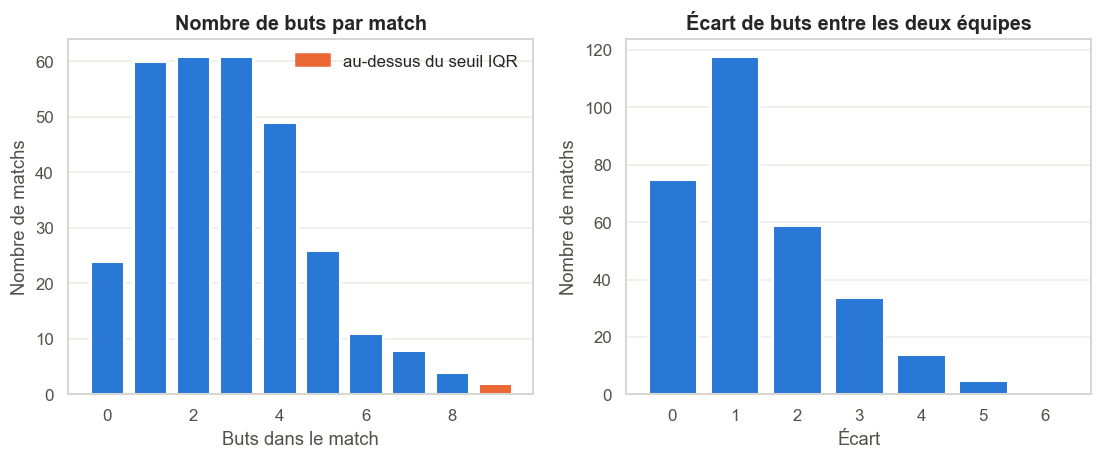

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
counts = played["total_goals"].astype(int).value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=[ORANGE if g > high else BLUE for g in counts.index],
            edgecolor="white", linewidth=2)
axes[0].set(title="Nombre de buts par match", xlabel="Buts dans le match", ylabel="Nombre de matchs")
axes[0].legend(handles=[Patch(color=ORANGE, label="au-dessus du seuil IQR")], frameon=False)
margin = played["margin"].astype(int).value_counts().sort_index()
axes[1].bar(margin.index, margin.values, color=BLUE, edgecolor="white", linewidth=2)
axes[1].set(title="Écart de buts entre les deux équipes", xlabel="Écart", ylabel="Nombre de matchs")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "01_distribution_buts.png")
plt.show()

**Décision : on conserve ces matchs.** Les contrôles de la section 7 montrent qu'ils sont cohérents avec le classement : ce sont de vrais matchs spectaculaires, pas des erreurs. Les retirer changerait les totaux de buts et donc le classement. La distribution des buts par match est naturellement asymétrique (beaucoup de 1-0, 2-1, quelques scores fleuves), ce qui fait réagir la règle de l'IQR sans qu'il y ait d'anomalie.

## 9. Analyse et visualisations

### 9.1 Classement final : points par match

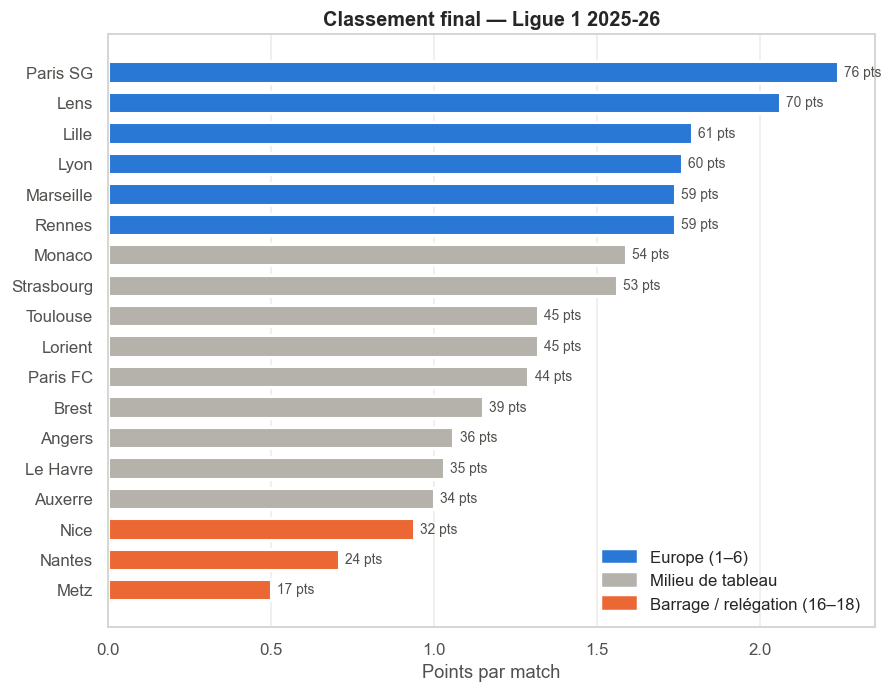

In [11]:
def zone(rank: int) -> str:
    if rank <= 6:
        return "Europe (1–6)"
    if rank >= n_teams - 2:
        return f"Barrage / relégation ({n_teams - 2}–{n_teams})"
    return "Milieu de tableau"


standings["points_per_match"] = (standings.points / standings.played).astype(float).round(2)
standings["zone"] = standings["rank"].astype(int).apply(zone)
ZONE_COLORS = dict(zip(sorted(standings.zone.unique(), key=lambda z: ("Europe" not in z, "Milieu" not in z)),
                       [BLUE, GREY, ORANGE]))

ranking = standings.sort_values("points_per_match")
fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(ranking.team, ranking.points_per_match, height=0.7,
               color=ranking.zone.map(ZONE_COLORS), edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"{p} pts" for p in ranking.points], padding=4, color=INK_2, fontsize=9)
ax.legend(handles=[Patch(color=c, label=z) for z, c in ZONE_COLORS.items()], loc="lower right", frameon=False)
ax.set(title=f"Classement final — Ligue 1 {season_label(SEASON)}", xlabel="Points par match", ylabel="")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "02_classement.png")
plt.show()

### 9.2 L'avantage du terrain existe-t-il ?

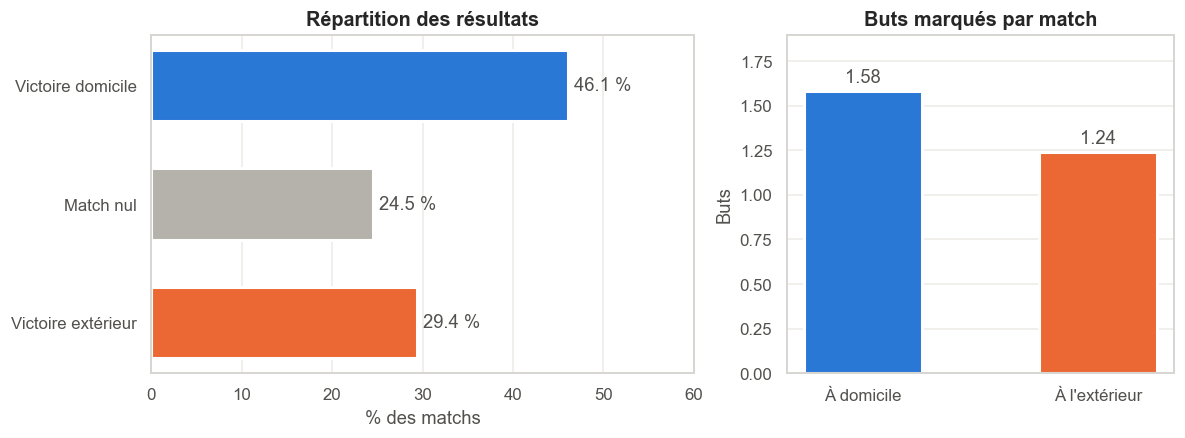

Victoires à domicile : 46.1% | à l'extérieur : 29.4%


In [12]:
shares = played["result"].value_counts(normalize=True).reindex(
    ["Victoire domicile", "Match nul", "Victoire extérieur"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.4, 1]})
bars = axes[0].barh(shares.index[::-1], shares.values[::-1] * 100, color=[ORANGE, GREY, BLUE],
                    height=0.6, edgecolor="white", linewidth=2)
axes[0].bar_label(bars, fmt="%.1f %%", padding=4, color=INK_2)
axes[0].set(title="Répartition des résultats", xlabel="% des matchs", xlim=(0, 60))
goals = pd.Series({"À domicile": played.home_goals.mean(), "À l'extérieur": played.away_goals.mean()})
bars = axes[1].bar(goals.index, goals.values, color=[BLUE, ORANGE], width=0.5, edgecolor="white", linewidth=2)
axes[1].bar_label(bars, fmt="%.2f", padding=3, color=INK_2)
axes[1].set(title="Buts marqués par match", ylabel="Buts", ylim=(0, goals.max() * 1.2))
for ax in axes:
    ax.grid(axis="y" if ax is axes[0] else "x", visible=False)
fig.savefig(FIGURES / "03_avantage_terrain.png")
plt.show()
print(f"Victoires à domicile : {shares['Victoire domicile']:.1%} | à l'extérieur : {shares['Victoire extérieur']:.1%}")

### 9.3 Chaque équipe à domicile et à l'extérieur

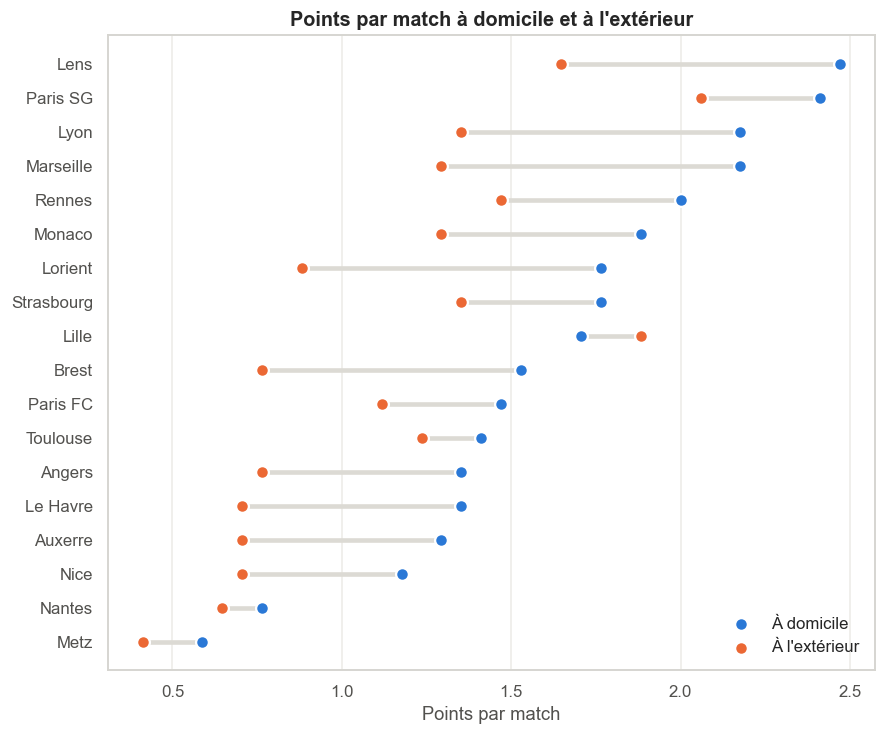

Plus gros écart domicile/extérieur : Lorient, Marseille, Lens
Meilleures à l'extérieur qu'à domicile : Lille


In [13]:
def points(gf, ga):
    return np.select([gf > ga, gf == ga], [3, 1], 0)


home_ppm = played.assign(p=points(played.home_goals, played.away_goals)).groupby("home")["p"].mean()
away_ppm = played.assign(p=points(played.away_goals, played.home_goals)).groupby("away")["p"].mean()
split = pd.DataFrame({"home": home_ppm, "away": away_ppm}).sort_values("home")
split["gap"] = split.home - split.away

fig, ax = plt.subplots(figsize=(9, 7.5))
y = np.arange(len(split))
ax.hlines(y, split.away, split.home, color=LIGHT_GREY, lw=3, zorder=1)
ax.scatter(split.home, y, color=BLUE, s=70, zorder=3, label="À domicile", edgecolor="white", linewidth=1.5)
ax.scatter(split.away, y, color=ORANGE, s=70, zorder=3, label="À l'extérieur", edgecolor="white", linewidth=1.5)
ax.set_yticks(y, split.index)
ax.set(title="Points par match à domicile et à l'extérieur", xlabel="Points par match")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "04_domicile_exterieur.png")
plt.show()
print("Plus gros écart domicile/extérieur :", ", ".join(split.gap.nlargest(3).index))
print("Meilleures à l'extérieur qu'à domicile :", ", ".join(split[split.gap < 0].index) or "aucune")

### 9.4 La course au titre, journée par journée

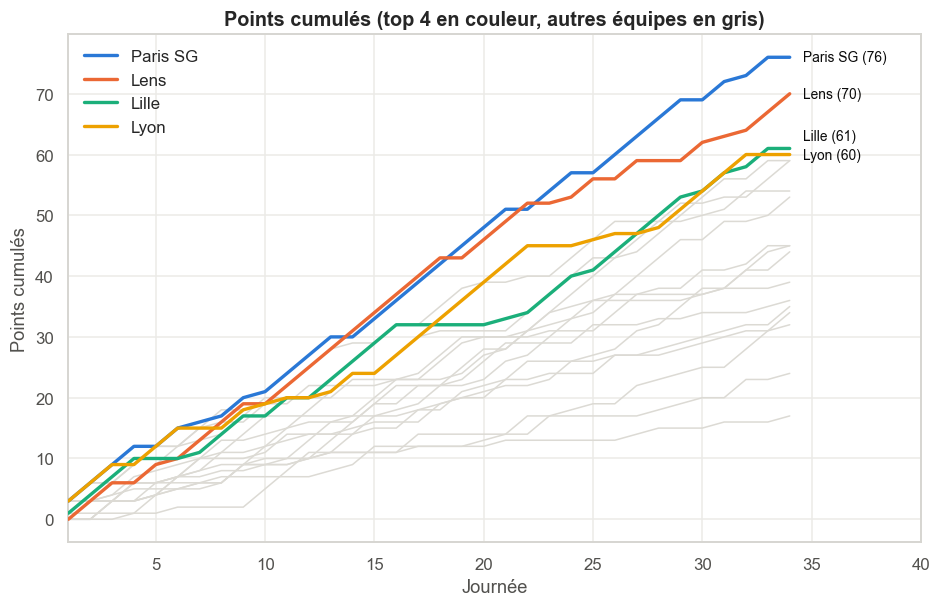

Leader après chaque journée : {'Paris SG': 22, 'Lens': 6, 'Lyon': 4, 'Angers': 1, 'Marseille': 1}
Nombre de changements de leader : 10


In [14]:
long = pd.concat([
    played.assign(team=played.home, pts=points(played.home_goals, played.away_goals)),
    played.assign(team=played.away, pts=points(played.away_goals, played.home_goals)),
])[["matchday", "team", "pts"]]
race = long.pivot_table(index="matchday", columns="team", values="pts", aggfunc="sum").fillna(0).cumsum()
top4 = standings.sort_values("rank").team.head(4).tolist()

fig, ax = plt.subplots(figsize=(10, 6))
for team in race.columns.difference(top4):
    ax.plot(race.index, race[team], color=LIGHT_GREY, lw=1, zorder=1)
final = race[top4].iloc[-1].sort_values()
label_y, previous = {}, -np.inf
min_gap = race.values.max() * 0.04          # écart vertical minimal entre deux étiquettes
for team, value in final.items():
    previous = max(value, previous + min_gap)
    label_y[team] = previous
for team, color in zip(top4, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(race.index, race[team], color=color, lw=2.2, label=team, zorder=3)
    ax.annotate(f"{team} ({race[team].iloc[-1]:.0f})", (race.index[-1], race[team].iloc[-1]),
                xytext=(race.index[-1] + 0.6, label_y[team]), textcoords="data",
                va="center", fontsize=9, color=INK)
ax.set_xlim(1, race.index.max() + 6)
ax.legend(frameon=False, loc="upper left")
ax.set(title="Points cumulés (top 4 en couleur, autres équipes en gris)",
       xlabel="Journée", ylabel="Points cumulés")
fig.savefig(FIGURES / "05_course_au_titre.png")
plt.show()

leaders = race.idxmax(axis=1)
changes = (leaders != leaders.shift()).sum() - 1
print(f"Leader après chaque journée : {leaders.value_counts().to_dict()}")
print(f"Nombre de changements de leader : {changes}")

### 9.5 Les scores les plus fréquents

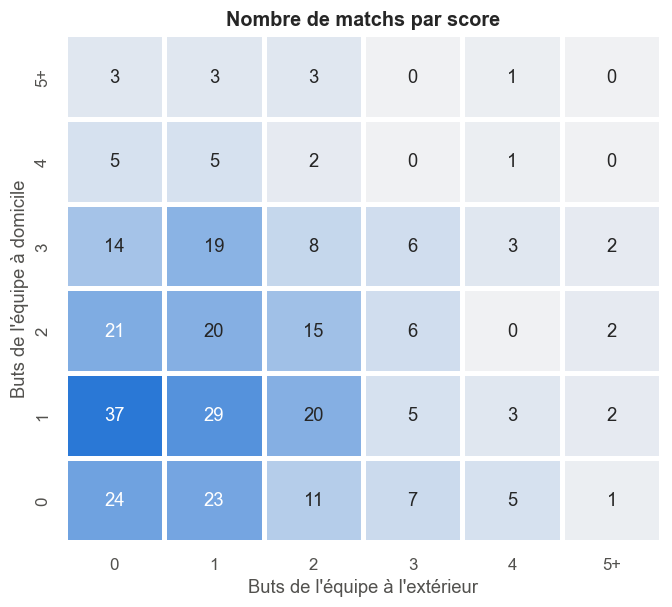

Scores les plus fréquents : 1-0 (37 fois), 1-1 (29 fois), 0-0 (24 fois)


In [15]:
cap = 5
grid = pd.crosstab(played.home_goals.astype(int).clip(upper=cap), played.away_goals.astype(int).clip(upper=cap))
grid = grid.reindex(index=range(cap + 1), columns=range(cap + 1), fill_value=0)
labels = [str(i) if i < cap else f"{cap}+" for i in range(cap + 1)]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(grid, annot=True, fmt="d", cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False,
            linewidths=2, linecolor="white", ax=ax, xticklabels=labels, yticklabels=labels)
ax.invert_yaxis()
ax.set(title="Nombre de matchs par score", xlabel="Buts de l'équipe à l'extérieur",
       ylabel="Buts de l'équipe à domicile")
fig.savefig(FIGURES / "06_scores_frequents.png")
plt.show()
top_scores = (played.home_goals.astype(str) + "-" + played.away_goals.astype(str)).value_counts().head(3)
print("Scores les plus fréquents :", ", ".join(f"{s} ({n} fois)" for s, n in top_scores.items()))

### 9.6 Profil attaque / défense

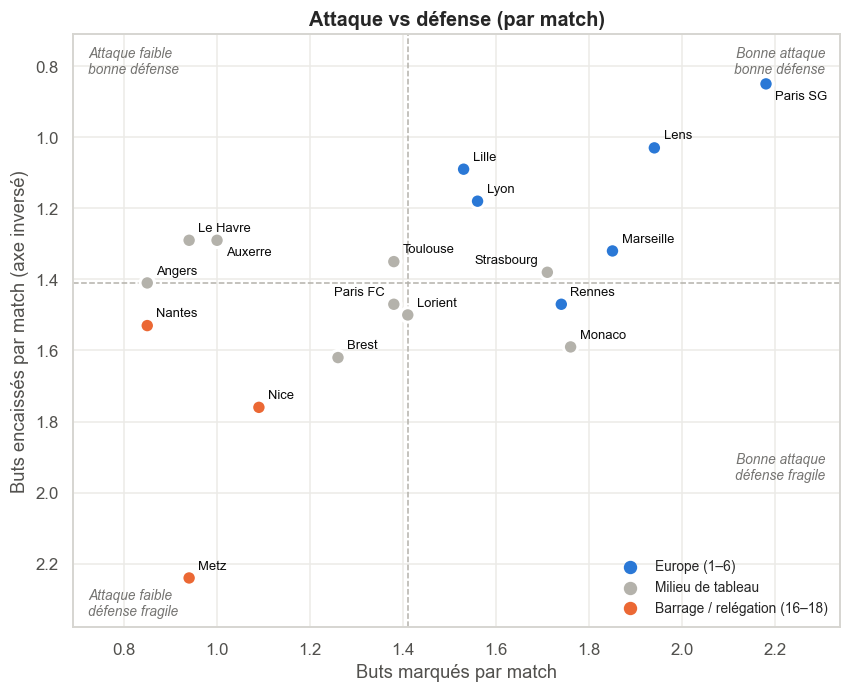

In [16]:
standings["gf_pm"] = (standings.goals_for / standings.played).astype(float).round(2)
standings["ga_pm"] = (standings.goals_against / standings.played).astype(float).round(2)

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(standings.gf_pm, standings.ga_pm, s=90, c=standings.zone.map(ZONE_COLORS),
           edgecolor="white", linewidth=2, zorder=3)
mx, my = standings.gf_pm.mean(), standings.ga_pm.mean()
ax.axvline(mx, color=GREY, lw=1, ls="--", zorder=1)
ax.axhline(my, color=GREY, lw=1, ls="--", zorder=1)
ax.margins(x=0.12, y=0.1)
ax.invert_yaxis()   # en haut = meilleure défense
quadrant = dict(color=INK_2, fontsize=9, style="italic", alpha=0.8, transform=ax.transAxes)
texts = [ax.text(0.02, 0.98, "Attaque faible\nbonne défense", va="top", **quadrant),
         ax.text(0.98, 0.98, "Bonne attaque\nbonne défense", ha="right", va="top", **quadrant),
         ax.text(0.02, 0.02, "Attaque faible\ndéfense fragile", **quadrant),
         ax.text(0.98, 0.25, "Bonne attaque\ndéfense fragile", ha="right", **quadrant)]
for z, c in ZONE_COLORS.items():
    ax.scatter([], [], color=c, label=z, s=60)
legend = ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.canvas.draw()
place_labels(ax, standings.gf_pm, standings.ga_pm, standings.team, obstacles=texts + [legend])
ax.set(title="Attaque vs défense (par match)", xlabel="Buts marqués par match",
       ylabel="Buts encaissés par match (axe inversé)")
fig.savefig(FIGURES / "07_attaque_defense.png")
plt.show()

## 10. Historique sur plusieurs saisons

Pour chaque saison de `HISTORY_SEASONS`, on scrape uniquement la page du **classement final** (une requête par saison, mise en cache). Remarques :
- jusqu'en 2022-23, la Ligue 1 comptait **20 équipes** (38 journées), puis 18 : on compare donc des **moyennes par match** ;
- la saison 2019-20 a été **arrêtée** à cause du Covid-19 (classement établi aux points par match).

In [17]:
f_history = DATA_RAW / "standings_history.csv"
if not REFRESH and f_history.exists():
    raw_history = pd.read_csv(f_history, sep=";")
else:
    frames = []
    for season in HISTORY_SEASONS:
        try:
            frames.append(parse_standings(get_page({"saison": season})).assign(season=season))
            print(f"\r  classement {season_label(season)} récupéré", end="")
        except ScrapingError as exc:
            print(f"\n  {season_label(season)} ignorée : {exc}")
    print()
    raw_history = pd.concat(frames, ignore_index=True)
    raw_history.to_csv(f_history, index=False, sep=";")

history_teams = clean_standings(raw_history)
history = (history_teams.sort_values(["season", "rank"])
           .groupby("season")
           .apply(lambda g: pd.Series({
               "teams": len(g),
               "goals_per_match": g.goals_for.sum() / (g.played.sum() / 2),
               "draw_rate": g.draws.sum() / g.played.sum(),
               "champion": g.team.iloc[0],
               "champion_ppm": g.points.iloc[0] / g.played.iloc[0],
               "title_gap": int(g.points.iloc[0] - g.points.iloc[1]),
           }), include_groups=False)
           .reset_index())
history["label"] = history.season.map(season_label)
history.round(2)

,season,teams,goals_per_match,draw_rate,champion,champion_ppm,title_gap,label
0,2014,20,2.49,0.23,Paris SG,2.18,8,2014-15
1,2015,20,2.53,0.28,Paris SG,2.53,31,2015-16
2,2016,20,2.61,0.25,Monaco,2.50,8,2016-17
3,2017,20,2.72,0.25,Paris SG,2.45,13,2017-18
4,2018,20,2.56,0.29,Paris SG,2.39,16,2018-19
5,2019,20,2.52,0.25,Paris SG,2.52,12,2019-20
6,2020,20,2.76,0.25,Losc,2.18,1,2020-21
7,2021,20,2.81,0.27,Paris SG,2.26,15,2021-22
8,2022,20,2.81,0.24,Paris SG,2.24,1,2022-23
9,2023,18,2.70,0.26,Paris SG,2.24,9,2023-24


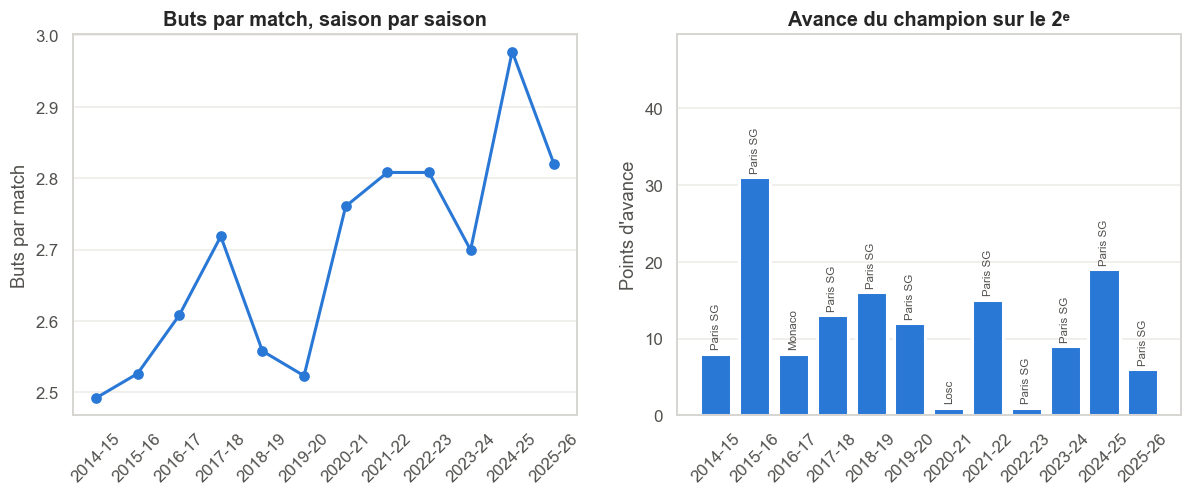

Titres par club : {'Paris SG': 10, 'Monaco': 1, 'Losc': 1}


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history.label, history.goals_per_match, color=BLUE, lw=2, marker="o", ms=6)
axes[0].set(title="Buts par match, saison par saison", ylabel="Buts par match")
axes[1].bar(history.label, history.title_gap, color=BLUE, edgecolor="white", linewidth=2)
for x, (gap, champ) in enumerate(zip(history.title_gap, history.champion)):
    axes[1].annotate(champ, (x, gap), xytext=(0, 3), textcoords="offset points",
                     ha="center", fontsize=7.5, color=INK_2, rotation=90, va="bottom")
axes[1].set(title="Avance du champion sur le 2ᵉ", ylabel="Points d'avance",
            ylim=(0, history.title_gap.max() * 1.6))
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "08_historique.png")
plt.show()
print("Titres par club :", history.champion.value_counts().to_dict())

## 11. Export

In [19]:
outputs = {
    f"matches_{SEASON}_clean.csv": matches,
    f"standings_{SEASON}_clean.csv": standings,
    "standings_history_clean.csv": history_teams,
    "seasons_summary.csv": history,
}
for name, frame in outputs.items():
    frame.to_csv(DATA_PROCESSED / name, index=False)
    print(f"{name:<32} {len(frame):>5} lignes")
print(f"\nGraphiques : {sorted(p.name for p in FIGURES.glob('*.png'))}")

matches_2025_clean.csv             306 lignes
standings_2025_clean.csv            18 lignes
standings_history_clean.csv        234 lignes
seasons_summary.csv                 12 lignes

Graphiques : ['01_distribution_buts.png', '02_classement.png', '03_avantage_terrain.png', '04_domicile_exterieur.png', '05_course_au_titre.png', '06_scores_frequents.png', '07_attaque_defense.png', '08_historique.png']


## 12. Conclusion

**Collecte.** Le classement et les résultats des 34 journées d'une saison, ainsi que les classements finaux de chaque saison depuis 2014-15, ont été scrapés sur TheFootData avec `requests` et `pandas.read_html`. Le scraper est volontairement sobre (pause entre les requêtes, cache, réutilisation des données brutes) pour respecter les conditions d'utilisation du site. La clé d'API, quand elle est utilisée, reste hors du code dans un fichier `.env`.

**Qualité des données.** Les noms de clubs, les scores, les dates sans année et la forme ont été convertis en variables exploitables. Les matchs sans score ne sont **pas imputés** (ce serait inventer un résultat), et les matchs à beaucoup de buts sont **conservés** (ils sont réels). Le contrôle principal, recalculer le classement à partir des résultats et le comparer au classement publié, valide l'ensemble de la collecte.

**Enseignements** (les chiffres exacts sont affichés sous chaque graphique) :
- l'avantage du terrain se mesure directement dans les résultats et dans les buts marqués ;
- certaines équipes dépendent beaucoup plus que d'autres de leurs matchs à domicile ;
- les données journée par journée permettent de suivre la course au titre et les changements de leader ;
- l'historique montre l'évolution du nombre de buts et de la domination du champion selon les saisons.

**Pistes.** Scraper les journées de toutes les saisons pour comparer l'avantage du terrain avant, pendant (huis clos de 2020-21) et après le Covid ; utiliser les pages de match pour ajouter les buteurs ; exploiter l'API dès son ouverture publique.

## Références
1. TheFootData, [Ligue 1](https://thefootdata.com/competitions/ligue-1?saison=2025), [conditions d'utilisation](https://thefootdata.com/cgu), [documentation de l'API](https://thefootdata.com/api).
2. The pandas development team, [pandas documentation](https://pandas.pydata.org/docs/) (`read_html`, `merge`, `pivot_table`).
3. Richardson, L., [Beautiful Soup documentation](https://www.crummy.com/software/BeautifulSoup/bs4/doc/).
4. Waskom, M. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.
5. Zhao, B. (2022). Web scraping. In *Encyclopedia of Big Data* (pp. 951–953). Springer.
6. Lee, K. J., & Simpson, J. A. (2014). Introduction to multiple imputation for dealing with missing data. *Respirology*, 19(2), 162–167.